# Customer Behavior & Churn Analysis

## Project overview
This project explores customer behavior and churn patterns in a structured customer dataset. The analysis reviews account characteristics, desktop and app activity, transactions, product-page engagement, wishlist and cart behavior, promotions and discounts, customer-service contacts, saved-card status, and push-notification status. The business objective is to identify observable patterns associated with customer churn and translate them into practical retention questions and priorities.

**Scope:** exploratory data analysis and descriptive business insights. The results show associations in the supplied dataset; they do not establish causation or provide a predictive model.

**Outcome interpretation used below:** `churn = 1` is treated as churned and `churn = 0` as retained, following the conventional binary encoding. The supplied files do not include a data dictionary, so this mapping should be confirmed with the data owner.


In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('customer_behaviour.csv', delimiter = ';')
df

,account length,location code,user id,credit card info save,push status,add to wishlist,desktop sessions,app sessions,desktop transactions,total product detail views,session duration,promotion clicks,avg order value,sale product views,discount rate per visited products,product detail view per app session,app transactions,add to cart per session,customer service calls,churn
0,128,415,3824657,no,yes,25,265,45,17,110,197,87,"244,7",91,"11,01",10,3,"2,7",1,0
1,107,415,3717191,no,yes,26,162,27,17,123,196,103,"254,4",103,"11,45","13,7",3,"3,7",1,0
2,137,415,3581921,no,no,0,243,41,10,114,121,110,"162,6",104,"7,32","12,2",5,"3,29",0,0
3,84,408,3759999,yes,no,0,299,51,5,71,62,88,"196,9",89,"8,86","6,6",7,"1,78",2,0
4,75,415,3306626,yes,no,0,167,28,13,113,148,122,"186,9",121,"8,41","10,1",3,"2,73",3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,192,415,4144276,no,yes,36,156,27,18,77,216,126,"279,1",83,"12,56","9,9",6,"2,67",2,0
3329,68,415,3703271,no,no,0,231,39,13,57,153,55,"191,3",123,"8,61","9,6",4,"2,59",3,0
3330,28,510,3288230,no,no,0,181,31,25,109,289,58,"191,9",91,"8,64","14,1",6,"3,81",2,0
3331,184,510,3646381,yes,no,0,214,36,14,105,160,84,"139,2",137,"6,26",5,10,"1,35",2,0


In [3]:
df.isnull().sum()

account length                         0
location code                          0
user id                                0
credit card info save                  0
push status                            0
add to wishlist                        0
desktop sessions                       0
app sessions                           0
desktop transactions                   0
total product detail views             0
session duration                       0
promotion clicks                       0
avg order value                        0
sale product views                     0
discount rate per visited products     0
product detail view per app session    0
app transactions                       0
add to cart per session                0
customer service calls                 0
churn                                  0
dtype: int64

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   account length                       3333 non-null   int64 
 1   location code                        3333 non-null   int64 
 2   user id                              3333 non-null   int64 
 3   credit card info save                3333 non-null   object
 4   push status                          3333 non-null   object
 5   add to wishlist                      3333 non-null   int64 
 6   desktop sessions                     3333 non-null   int64 
 7   app sessions                         3333 non-null   int64 
 8   desktop transactions                 3333 non-null   int64 
 9   total product detail views           3333 non-null   int64 
 10  session duration                     3333 non-null   int64 
 11  promotion clicks                     3333 n

In [5]:
df.columns = [c.lower().replace(' ', '_') for c in df.columns]
df.columns

Index(['account_length', 'location_code', 'user_id', 'credit_card_info_save',
       'push_status', 'add_to_wishlist', 'desktop_sessions', 'app_sessions',
       'desktop_transactions', 'total_product_detail_views',
       'session_duration', 'promotion_clicks', 'avg_order_value',
       'sale_product_views', 'discount_rate_per_visited_products',
       'product_detail_view_per_app_session', 'app_transactions',
       'add_to_cart_per_session', 'customer_service_calls', 'churn'],
      dtype='object')

In [13]:
df['avg_order_value'] = df['avg_order_value'].replace(',', '.', regex = True).astype(float)
df['discount_rate_per_visited_products'] = df['discount_rate_per_visited_products'].replace(',', '.', regex = True).astype(float)
df['add_to_cart_per_session'] = df['add_to_cart_per_session'].replace(',','.', regex = True).astype(float)
df['product_detail_view_per_app_session'] = df['product_detail_view_per_app_session'].replace(',','.', regex = True).astype(float)

df.info()
len(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   account_length                       3333 non-null   int64  
 1   location_code                        3333 non-null   int64  
 2   user_id                              3333 non-null   int64  
 3   credit_card_info_save                3333 non-null   object 
 4   push_status                          3333 non-null   object 
 5   add_to_wishlist                      3333 non-null   int64  
 6   desktop_sessions                     3333 non-null   int64  
 7   app_sessions                         3333 non-null   int64  
 8   desktop_transactions                 3333 non-null   int64  
 9   total_product_detail_views           3333 non-null   int64  
 10  session_duration                     3333 non-null   int64  
 11  promotion_clicks              

3333

## Data overview and preparation notes

- **Dataset size:** 3,333 customer records and 20 columns.
- **Completeness:** 0 missing values across the dataset.
- **Uniqueness:** 3,333 unique `user id` values; 0 exact duplicate rows.
- **Numeric formatting:** four measurement columns are stored with decimal commas in the CSV and are converted to floating-point values in the existing preparation code: `avg_order_value`, `discount_rate_per_visited_products`, `product_detail_view_per_app_session`, and `add_to_cart_per_session`.
- **Interpretation caution:** the file does not document measurement units, the meaning of the location codes, or the exact operational definitions of the behavioral fields.


In [27]:
#Way 1
numeric_cols = [c for c in df.columns if df[c].dtypes != 'O' ]
# Way 2
numeric_cols2 = df.select_dtypes(include = 'number').columns.tolist()
#Way 3
numeric_cols3 = [df.columns[i] for i in range(0, len(df.columns)) if df[df.columns[i]].dtypes != 'O']
print(len(numeric_cols))
print(len(numeric_cols2))
print(len(numeric_cols3))

18
18
18


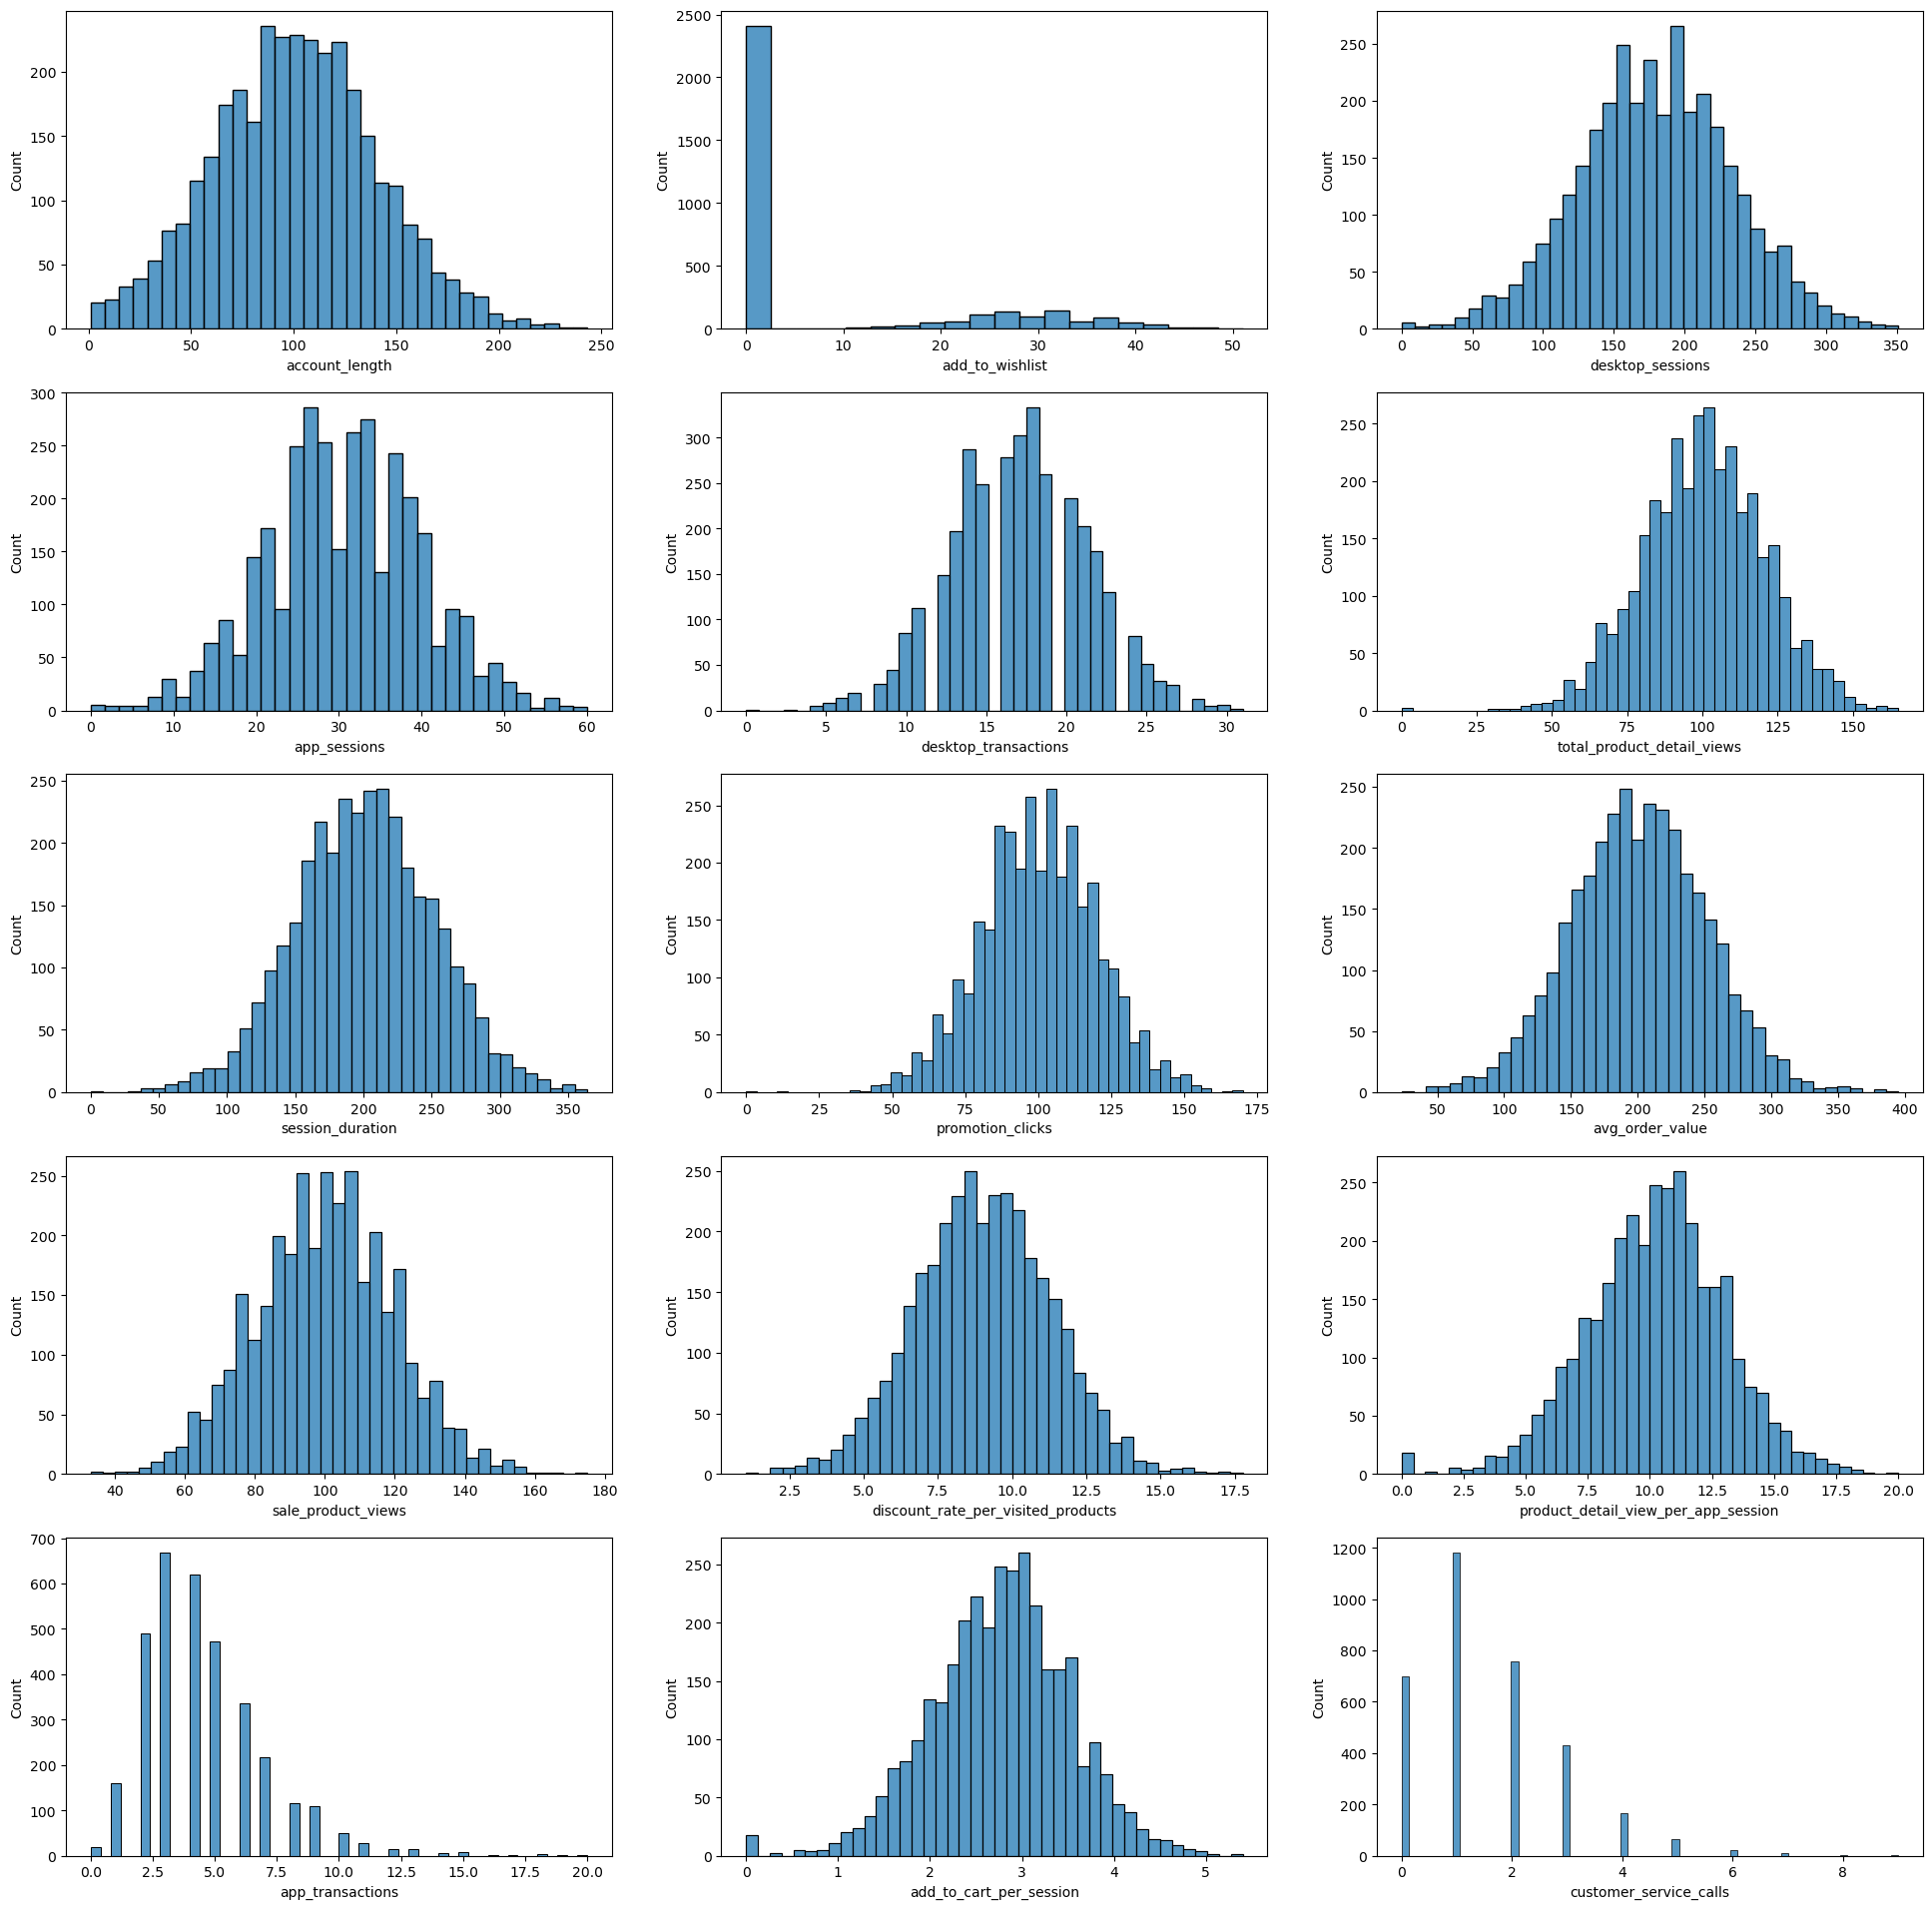

In [32]:
numeric_columns = ['account_length', 'add_to_wishlist', 'desktop_sessions','app_sessions', 'desktop_transactions',
                   'total_product_detail_views','session_duration', 'promotion_clicks', 'avg_order_value','sale_product_views',
                   'discount_rate_per_visited_products','product_detail_view_per_app_session', 'app_transactions',
                   'add_to_cart_per_session', 'customer_service_calls']
#fig, ax = plt.subplots(5,3, figsize = (24,24))
#axes = axes.flatten()
#for i in range(5):
    #for j in range(3):
        #sns.histplot(df[numeric_cols[3*i+j]], ax = ax[i,j])

fig, axes = plt.subplots(5,3, figsize = (24,24))
axes = axes.flatten()
for col, ax in zip(numeric_columns, axes):
    sns.histplot(df[col], ax = ax)

## Business insights — selected numerical distributions

- **Wishlist usage is concentrated at zero:** 2,411 of 3,333 records (72.3%) have zero wishlist additions. The median is also zero, while the mean is 8.10. This suggests wishlist activity is absent for most records and may be useful as a behavioral segmentation feature; it does not explain why customers do not use it.
- **Digital activity is distributed around central values:** mean desktop sessions are 179.8 (median 179) and mean app sessions are 30.6 (median 31). The distributions show meaningful variation between customers, supporting segmentation rather than relying on a single average.
- **Customer-service contacts are right-skewed:** the mean is 1.56 calls and the median is 1; the observed range is 0–9. A relatively small high-contact group deserves separate review (quantified in the churn section below).
- **App transactions are also concentrated at relatively low counts:** the mean is 4.48, the median is 4, and the maximum is 20. The distribution is not symmetric, so the median and segment-level comparisons are useful alongside the mean.

The histogram is descriptive. Because the file does not define units for `session_duration` or `avg_order_value`, no time or currency unit is assigned to those measures.


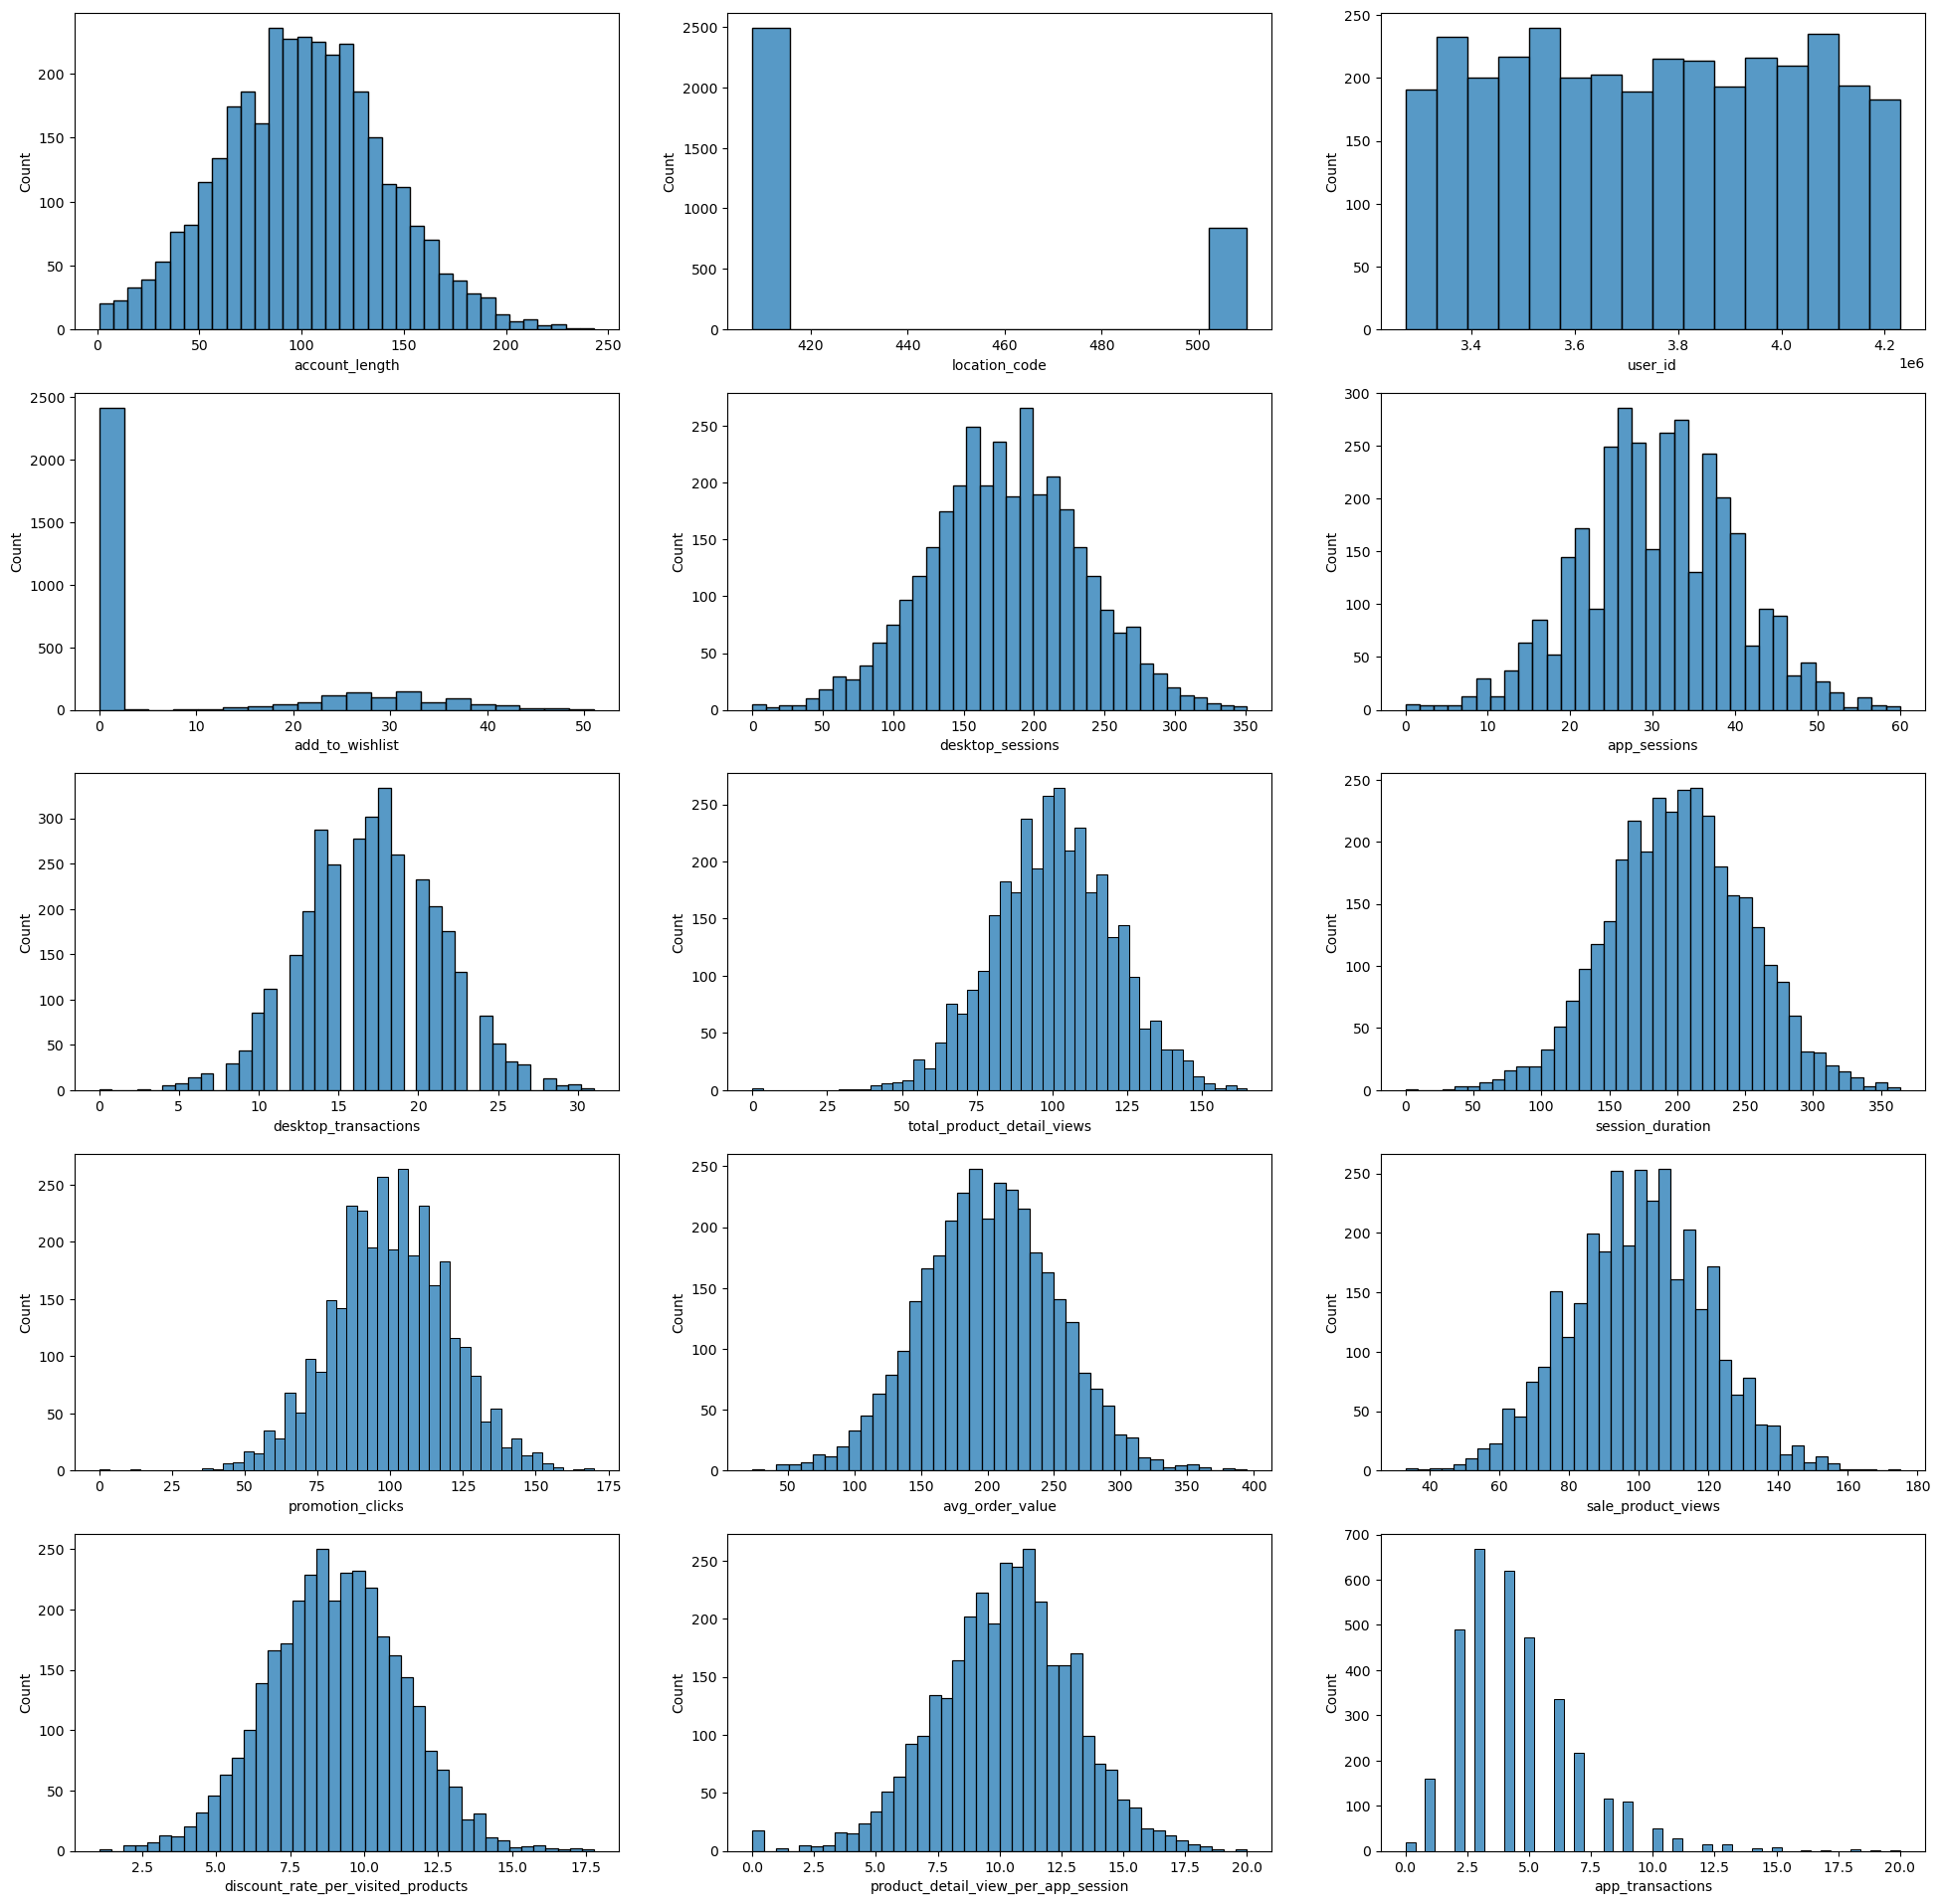

In [21]:
#numeric_cols = [c for c in df.columns if (df[c].dtypes == 'int64') |(df[c].dtypes == 'float64')]
#len(numeric_cols)
numeric_columns = df.select_dtypes(include = 'number').columns.tolist()

fig,ax = plt.subplots(5,3, figsize = (24,24))
for i in range(5):
    for j in range(3):
        sns.histplot(df[numeric_columns[3*i+j]], ax = ax[i,j])

## Business insights — automatically selected numeric columns

This second histogram set is generated from the first 15 columns returned by `select_dtypes(include='number')` and therefore repeats several measures from the previous figure. It also includes `location_code` (a category-like code) and `user_id` (an identifier), whose histogram shapes should not be interpreted as behavioral distributions. The fixed 5×3 layout also leaves later numeric fields out of this figure, including `add_to_cart_per_session`, `customer_service_calls`, and `churn`.

**Takeaway:** the manually selected behavioral-variable chart above is more suitable for business interpretation. The code and original chart are preserved as supplied; this note documents the scope limitation rather than changing the analysis code.


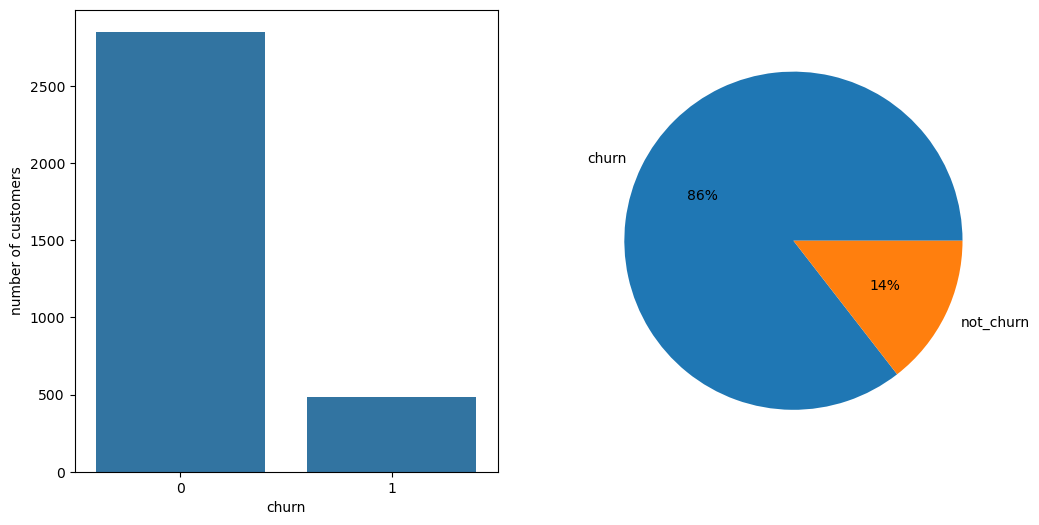

In [9]:
fig, ax = plt.subplots(1,2, figsize = (12,6))

plt.pie(df['churn'].value_counts(), labels = ['churn', 'not_churn'],autopct = '%.0f%%')
cp = sns.countplot(x= df['churn'], ax = ax[0])
cp.set_xlabel('churn')
cp.set_ylabel('number of customers')
plt.show()

## Business insights — churn distribution

| Churn code | Customers | Share |
|---|---:|---:|
| `0` (treated as retained) | 2,850 | 85.5% |
| `1` (treated as churned) | 483 | 14.5% |
| **Total** | **3,333** | **100.0%** |

- Under the stated binary-encoding assumption, the observed churn rate is **14.5%** (483 customers); the remaining **85.5%** are coded `0`.
- The class distribution is imbalanced, so a future predictive model should not be evaluated on accuracy alone.
- **Chart-label issue in the original pie plot:** `value_counts()` returns the classes in descending frequency order here (`0` then `1`), but the code assigns labels `['churn', 'not_churn']` in that same order. If `1` means churn, the pie labels are therefore reversed. The adjacent count plot correctly shows the numeric classes (`0` and `1`); the counts and percentages in this table are calculated directly from the supplied CSV.


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   account_length                       3333 non-null   int64  
 1   location_code                        3333 non-null   int64  
 2   user_id                              3333 non-null   int64  
 3   credit_card_info_save                3333 non-null   object 
 4   push_status                          3333 non-null   object 
 5   add_to_wishlist                      3333 non-null   int64  
 6   desktop_sessions                     3333 non-null   int64  
 7   app_sessions                         3333 non-null   int64  
 8   desktop_transactions                 3333 non-null   int64  
 9   total_product_detail_views           3333 non-null   int64  
 10  session_duration                     3333 non-null   int64  
 11  promotion_clicks              

In [41]:
#Way 1
for i in df.select_dtypes(include = 'O').columns:
    df[i] = df[i].replace([0,1], ['No', 'Yes'])
#Way 2
for i in df.columns:
    if df[i].dtypes == 'O':
        df[i].replace([0,1], ['No', 'Yes'])

['account_length', 'credit_card_info_save', 'push_status']

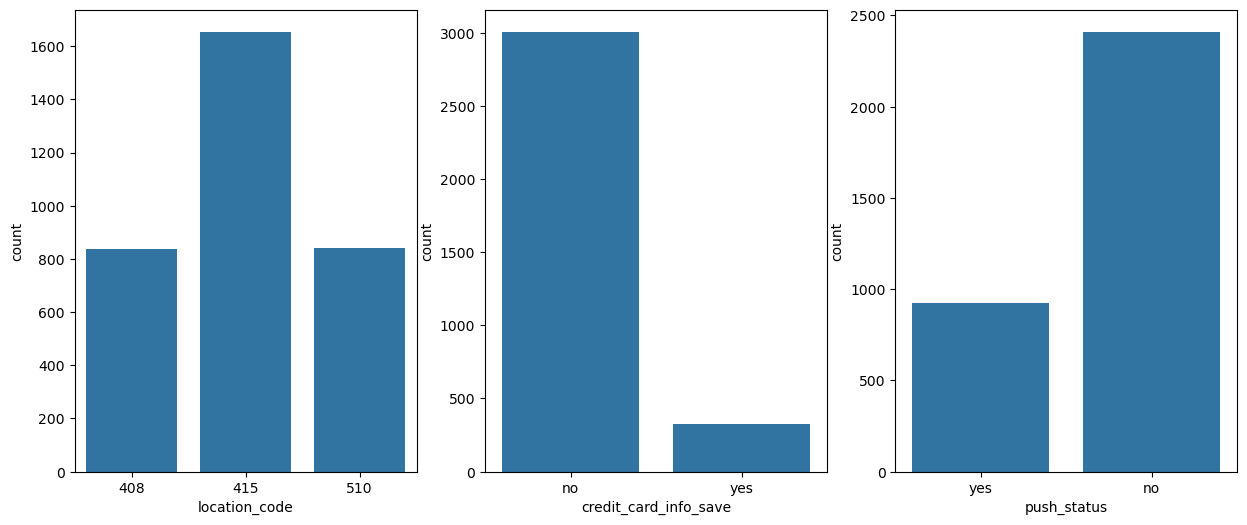

In [48]:
cat_cols = [c for c in df.columns if (df[c].dtypes == 'O' )| (c == 'location_code')]
fig, ax = plt.subplots(1, len(cat_cols), figsize = (15, 6))
ax = ax.flatten()
for col, ax in zip(cat_cols, ax):
    #Way 1
    #size = df[col].value_counts()
    #sns.barplot(x = size.index, y = size, ax = ax)
    #Way 2 
    sns.countplot(x = df[col] , ax = ax)

## Business insights — categorical distributions and churn segments

### Distribution of categorical fields

- `location_code = 415` represents 1,655 records (49.7%); codes `408` and `510` each represent about one quarter of the sample.
- `credit_card_info_save = yes` appears in 323 records (9.7%).
- `push_status = yes` appears in 922 records (27.7%).

### Churn rate within each segment

| Segment | Customers | Churned (`churn=1`) | Segment churn rate |
|---|---:|---:|---:|
| `push_status = yes` | 922 | 80 | 8.7% |
| `push_status = no` | 2,411 | 403 | 16.7% |
| `credit_card_info_save = yes` | 323 | 137 | 42.4% |
| `credit_card_info_save = no` | 3,010 | 346 | 11.5% |

- **Push status:** the `yes` segment has a lower observed churn rate (8.7%) than the `no` segment (16.7%), a difference of 8.0 percentage points. This is an association, not proof that push notifications reduce churn; the meaning of the status field is not defined in the source file.
- **Saved-card status:** the `yes` segment has a much higher observed churn rate (42.4%) than the `no` segment (11.5%). Because the `yes` segment contains 323 customers only and the field definition is undocumented, validate the variable's meaning, capture timing, and data quality before taking action.
- **Location code:** observed churn rates are very similar across `408` (14.6%), `415` (14.3%), and `510` (14.9%). The codes do not show a strong separation in this descriptive comparison; no geographic interpretation is possible without a code lookup.


# Overall business insights and recommendations

## Key findings

1. **Customer-service contacts are a strong descriptive risk signal.** Among customers with **4 or more** service calls, 138 of 267 are coded as churned, a segment churn rate of **51.7%**. This group is 8.0% of the dataset. Consider prioritizing these customers for service-recovery review and investigating the issues generating repeat contacts.
2. **Push status is associated with a lower churn rate.** The observed rates are 8.7% for `yes` and 16.7% for `no`. Treat this as a hypothesis to test, not a causal result; clarify whether the field means opt-in, enabled status, or successful delivery.
3. **Saved-card status needs validation.** Churn is 42.4% for `yes` versus 11.5% for `no`. This unexpected difference should prompt a field-definition and cohort-quality check before any commercial conclusion is drawn.
4. **More activity does not necessarily correspond to more app transactions.** Customers coded `churn=1` average 206.9 desktop sessions and 35.2 app sessions, versus 175.2 and 29.8 for `churn=0`. Yet mean app transactions are 4.16 versus 4.53. This may justify investigating the app journey and conversion funnel; it does not prove friction by itself.
5. **Wishlist engagement is lower on average among churned records.** The mean is 5.12 for `churn=1` versus 8.60 for `churn=0`; however, the median is zero for both groups, so interpret the mean alongside the high number of zero-wishlist records.
6. **Location code is not a strong differentiator** in the observed sample, with segment rates ranging only from 14.3% to 14.9%.

## Recommended next steps

- Validate the `churn` coding and obtain a data dictionary for `credit_card_info_save`, `push_status`, location codes, and all measurement units.
- Review root causes and service transcripts/ticket categories for customers with 4+ service calls; assess a targeted service-recovery workflow.
- Run a controlled experiment before concluding that push communication changes retention.
- Audit the saved-card segment and compare it with account tenure, acquisition source, service contacts, and other customer attributes.
- Examine the app funnel (sessions → product views → cart → transactions) using event-level data to locate possible drop-off points.

## Analysis boundaries

These are descriptive comparisons from one supplied snapshot. There is no date/time field or data dictionary, no documented currency/time units, and no external mapping for location codes. No hypothesis tests, causal analysis, or churn-prediction model were performed. The class meaning `1 = churned` is an explicit working assumption and should be confirmed.
